# 03. Machine Learning Modeling & Benchmarking — CampusWell RiskLab

## Section 1: Problem Formulation & Evaluation Strategy

Welcome to the **CampusWell RiskLab** Machine Learning Benchmarking notebook.

### Supervised Classification Framing
Our objective is to classify university students into three synthetic mental health risk tiers:
$$\mathcal{Y} = \{\text{Low}, \text{Medium}, \text{High}\}$$

This multi-class classification problem requires balancing sensitivity across all risk categories while preventing severe diagnostic blunders, specifically ensuring students facing elevated psychological distress are never misdiagnosed into benign tiers.

### Metric Selection Hierarchy
1. **Primary Metric — Weighted F1-score ($F_1^{\text{weighted}}$):**
   Calculates the harmonic mean of precision and recall for each category weighted by its empirical support:
   $$F_1^{\text{weighted}} = \sum_{c \in \mathcal{Y}} \frac{N_c}{N} F_{1, c}$$
   This captures overall performance while penalizing false positives and false negatives proportionately across classes.
2. **Secondary Metric — Macro F1-score ($F_1^{\text{macro}}$):**
   Unweighted arithmetic average of per-class F1-scores:
   $$F_1^{\text{macro}} = \frac{1}{|\mathcal{Y}|} \sum_{c \in \mathcal{Y}} F_{1, c}$$
   Evaluates uncompromised multi-class equilibrium and guarantees that the smaller High-risk cohort ($N=600$) is not marginalized by larger cohorts.
3. **Tertiary Metric — Multi-Class ROC-AUC (One-vs-Rest):**
   Evaluates class separability across decision thresholds independent of default argmax probability classification.
4. **Safety Constraint — Severe Misclassification Rate:**
   Students in the `High` risk category must never be assigned a `Low` risk classification ($	ext{Confusion Matrix}[\text{High}, \text{Low}] \to 0$).

### Validation Strategy & Leakage Prevention
All evaluation is conducted using **Stratified 5-Fold Cross-Validation** on the training partition ($N = 1,600$). In each fold:
- 1,280 samples form the training fold, and 320 samples form the validation fold.
- Preprocessing steps (median imputation, feature scaling, one-hot encoding, and engineered feature transformations) are strictly wrapped inside scikit-learn `Pipeline` objects.
- All statistics (imputation medians, standard scaling means and variances) are calculated exclusively on the training fold and applied to the validation fold.

## Section 2: Environment Setup & Data Ingestion

We import necessary scientific computing libraries, project configuration constants, and modular pipeline constructors.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

from src.config import (
    RANDOM_STATE,
    CV_FOLDS,
    TARGET_CLASSES,
    NUMERICAL_FEATURES,
    NOMINAL_FEATURES,
    ORDINAL_FEATURES,
    BINARY_FEATURES,
    ENGINEERED_NUMERICAL_FEATURES
)
from src.features.preprocessing import build_model_pipeline
from src.steps.preprocessing import load_splits
from src.utils.metrics import cross_val_metrics_summary, save_metrics, load_metrics
print("Scientific computing libraries and project modules successfully loaded.")


Scientific computing libraries and project modules successfully loaded.


## Section 3: Training Data Ingestion & Class Balance Verification

We ingest the stratified training dataset ($N = 1,600$, 15 raw feature columns). The test dataset ($N = 400$) is isolated until final post-optimization evaluation.

In [2]:
X_train, X_test, y_train, y_test = load_splits()
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print("\nTarget class distribution in X_train:")
dist_df = pd.DataFrame({
    'Count': y_train.value_counts(),
    'Proportion': y_train.value_counts(normalize=True).round(4)
})
print(dist_df)

X_train shape: (1600, 15)
y_train shape: (1600,)

Target class distribution in X_train:
                    Count  Proportion
Mental_Health_Risk                   
High                  544        0.34
Medium                528        0.33
Low                   528        0.33


## Section 4: Model Taxonomy & Algorithmic Rationale

We benchmark four diverse algorithm families representing linear, bagging, gradient boosting, and histogram-based paradigms:

1. **Multinomial Logistic Regression:**
   - Linear decision boundaries with softmax probability outputs.
   - High interpretability via learned feature coefficients $\beta_j$.
   - Numerical features are standardized via `StandardScaler()`.
2. **HistGradientBoostingClassifier:**
   - Modern histogram-based gradient boosting optimized for tabular data.
   - Bins continuous numerical values into 256 discrete bins for computational speed and resistance to noise.
   - Does not require numerical feature scaling.
3. **Random Forest Classifier:**
   - Bagged ensemble of 100 de-correlated decision trees.
   - Evaluates whether random feature subspace selection reduces variance.
4. **XGBoost (Extreme Gradient Boosting):**
   - Exact greedy tree boosting optimizing second-order Taylor expansions of the multi-class log loss.
   - Regularized with $L_1$ and $L_2$ leaf penalties.

In [3]:
models = {
    "Logistic Regression": (
        LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
        True
    ),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(random_state=RANDOM_STATE),
        False
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=100),
        False
    ),
    "XGBoost": (
        XGBClassifier(random_state=RANDOM_STATE, eval_metric="mlogloss", verbosity=0),
        False
    )
}

pipelines = {}
for name, (clf, scale) in models.items():
    pipelines[name] = build_model_pipeline(clf, scale_numerical=scale)
print(f"Initialized {len(pipelines)} end-to-end model pipelines.")

Initialized 4 end-to-end model pipelines.


## Section 5: Stratified 5-Fold Cross-Validation Execution

Each pipeline is evaluated across 5 stratified folds on the training partition ($N=1,600$). Metrics tracked include Accuracy, Weighted F1, Macro F1, Weighted Precision, Weighted Recall, and Multiclass ROC-AUC OvR.

In [4]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "weighted_f1": "f1_weighted",
    "macro_f1": "f1_macro",
    "weighted_precision": "precision_weighted",
    "weighted_recall": "recall_weighted",
    "roc_auc_ovr": "roc_auc_ovr"
}

cv_results = {}
for name, pipeline in pipelines.items():
    print(f"Cross-validating: {name}...")
    if name == "XGBoost":
        le = LabelEncoder()
        le.fit(TARGET_CLASSES)
        y_fit = pd.Series(le.transform(y_train), index=y_train.index)
        scores = cross_validate(pipeline, X_train, y_fit, cv=cv, scoring=scoring, n_jobs=-1)
    else:
        scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results[name] = cross_val_metrics_summary(scores)
    print(f"  -> {name} Weighted F1: {cv_results[name]['test_weighted_f1']['mean']:.4f} +/- {cv_results[name]['test_weighted_f1']['std']:.4f}")

Cross-validating: Logistic Regression...


  -> Logistic Regression Weighted F1: 0.7564 +/- 0.0204
Cross-validating: HistGradientBoosting...


  -> HistGradientBoosting Weighted F1: 0.6842 +/- 0.0120
Cross-validating: Random Forest...


  -> Random Forest Weighted F1: 0.6709 +/- 0.0316
Cross-validating: XGBoost...


  -> XGBoost Weighted F1: 0.6788 +/- 0.0210


## Section 6: Cross-Validation Benchmarking Results

We compile the cross-validation statistics into a structured comparison table.

In [5]:
summary_rows = []
for name, metrics in cv_results.items():
    summary_rows.append({
        "Model": name,
        "Mean Weighted F1": round(metrics["test_weighted_f1"]["mean"], 4),
        "Std Weighted F1": round(metrics["test_weighted_f1"]["std"], 4),
        "Mean Macro F1": round(metrics["test_macro_f1"]["mean"], 4),
        "Std Macro F1": round(metrics["test_macro_f1"]["std"], 4),
        "Mean Accuracy": round(metrics["test_accuracy"]["mean"], 4),
        "Std Accuracy": round(metrics["test_accuracy"]["std"], 4),
        "Mean ROC-AUC (OvR)": round(metrics["test_roc_auc_ovr"]["mean"], 4),
        "Std ROC-AUC": round(metrics["test_roc_auc_ovr"]["std"], 4)
    })

benchmark_df = pd.DataFrame(summary_rows).sort_values(by="Mean Weighted F1", ascending=False).reset_index(drop=True)
benchmark_df

,Model,Mean Weighted F1,Std Weighted F1,Mean Macro F1,Std Macro F1,Mean Accuracy,Std Accuracy,Mean ROC-AUC (OvR),Std ROC-AUC
0,Logistic Regression,0.7564,0.0204,0.7558,0.0203,0.7563,0.0204,0.9063,0.0084
1,HistGradientBoosting,0.6842,0.0120,0.6833,0.0120,0.6850,0.0142,0.8587,0.0122
2,XGBoost,0.6788,0.0210,0.6779,0.0211,0.6787,0.0221,0.8538,0.0142
3,Random Forest,0.6709,0.0316,0.6700,0.0316,0.6738,0.0328,0.8438,0.0158


## Section 7: Visualizing Model Performance Comparisons

We display side-by-side bar plots comparing the models on Weighted F1-score and Multi-class ROC-AUC (OvR) with cross-validation standard deviation error bars.

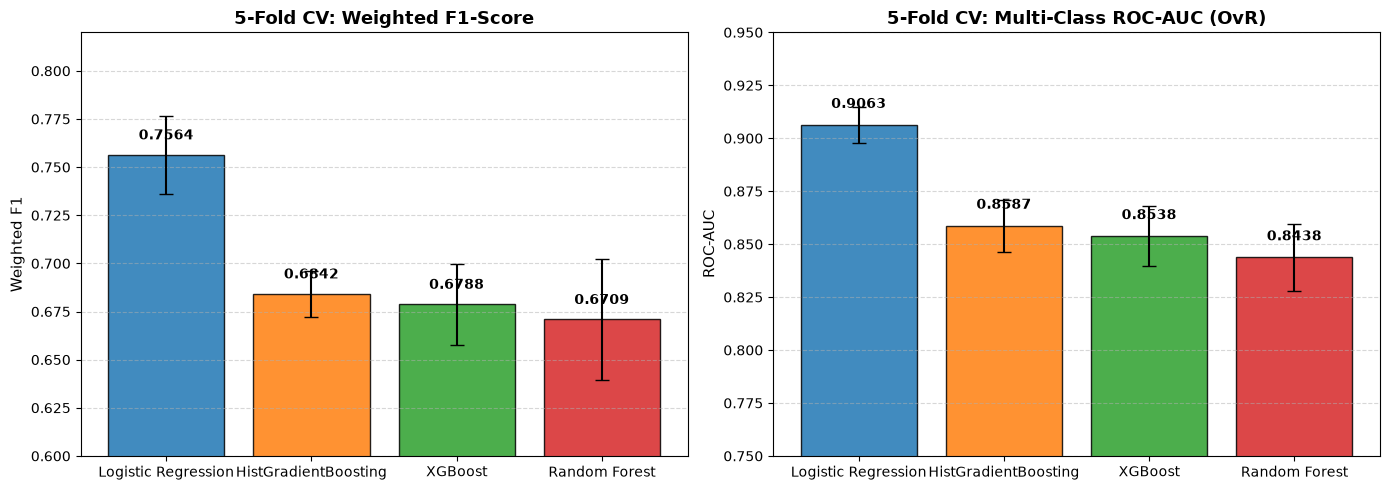

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    benchmark_df["Model"],
    benchmark_df["Mean Weighted F1"],
    yerr=benchmark_df["Std Weighted F1"],
    capsize=5,
    color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"],
    alpha=0.85,
    edgecolor="black"
)
axes[0].set_title("5-Fold CV: Weighted F1-Score", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Weighted F1", fontsize=11)
axes[0].set_ylim(0.60, 0.82)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for i, v in enumerate(benchmark_df["Mean Weighted F1"]):
    axes[0].text(i, v + 0.008, f"{v:.4f}", ha="center", fontweight="bold")

axes[1].bar(
    benchmark_df["Model"],
    benchmark_df["Mean ROC-AUC (OvR)"],
    yerr=benchmark_df["Std ROC-AUC"],
    capsize=5,
    color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"],
    alpha=0.85,
    edgecolor="black"
)
axes[1].set_title("5-Fold CV: Multi-Class ROC-AUC (OvR)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("ROC-AUC", fontsize=11)
axes[1].set_ylim(0.75, 0.95)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
for i, v in enumerate(benchmark_df["Mean ROC-AUC (OvR)"]):
    axes[1].text(i, v + 0.008, f"{v:.4f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

## Section 8: Out-of-Fold Error Analysis & Confusion Matrices

To inspect diagnostic stability, we generate out-of-fold predictions using `cross_val_predict` across the 5 training folds for both Logistic Regression and HistGradientBoosting.

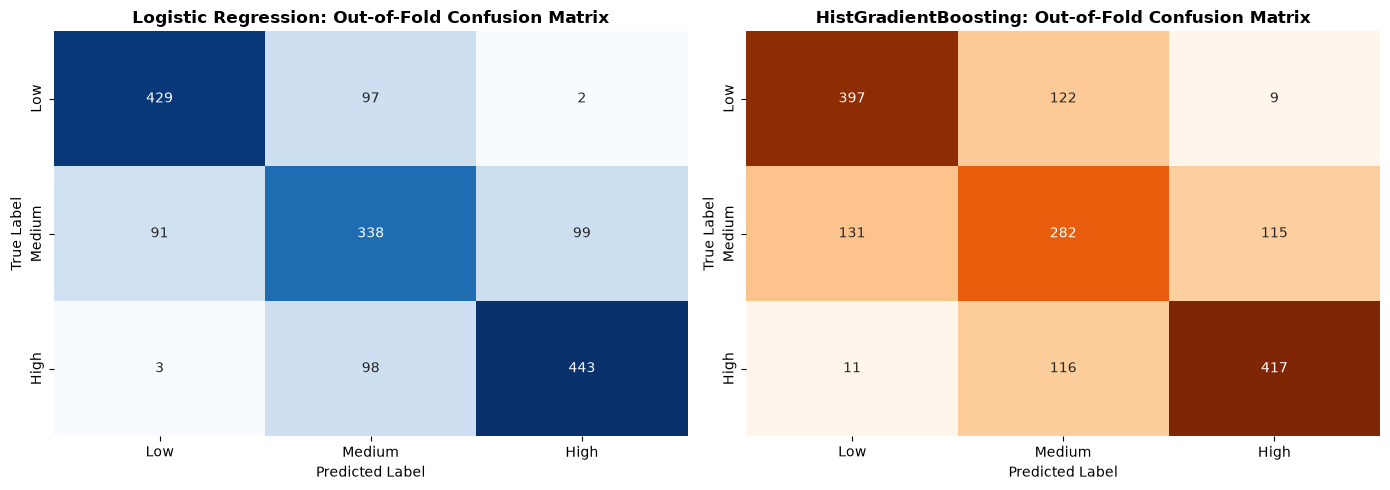

Logistic Regression OOF Classification Report:
              precision    recall  f1-score   support

         Low     0.8143    0.8143    0.8143       544
      Medium     0.8203    0.8125    0.8164       528
        High     0.6341    0.6402    0.6371       528

    accuracy                         0.7562      1600
   macro avg     0.7563    0.7557    0.7559      1600
weighted avg     0.7568    0.7562    0.7565      1600



In [7]:
lr_oof_pred = cross_val_predict(pipelines["Logistic Regression"], X_train, y_train, cv=cv, n_jobs=-1)
hgb_oof_pred = cross_val_predict(pipelines["HistGradientBoosting"], X_train, y_train, cv=cv, n_jobs=-1)

cm_lr = confusion_matrix(y_train, lr_oof_pred, labels=TARGET_CLASSES)
cm_hgb = confusion_matrix(y_train, hgb_oof_pred, labels=TARGET_CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=TARGET_CLASSES, yticklabels=TARGET_CLASSES, cbar=False)
axes[0].set_title("Logistic Regression: Out-of-Fold Confusion Matrix", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Predicted Label", fontsize=10)
axes[0].set_ylabel("True Label", fontsize=10)

sns.heatmap(cm_hgb, annot=True, fmt="d", cmap="Oranges", ax=axes[1],
            xticklabels=TARGET_CLASSES, yticklabels=TARGET_CLASSES, cbar=False)
axes[1].set_title("HistGradientBoosting: Out-of-Fold Confusion Matrix", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted Label", fontsize=10)
axes[1].set_ylabel("True Label", fontsize=10)

plt.tight_layout()
plt.show()

print("Logistic Regression OOF Classification Report:")
print(classification_report(y_train, lr_oof_pred, target_names=TARGET_CLASSES, digits=4))

## Section 9: Multiclass ROC Curves & Discriminative Confidence

We compute out-of-fold predicted class probabilities for Logistic Regression and plot the One-vs-Rest ROC curve for each risk tier.